# Phase 4 – Court Judgment Prediction (CJPE) with the Phase-1 legal LM
Binary classification of long Indian court judgments (0/1). Train on `train.json`, select on `dev.json`, report on `test.json`.

**Pipeline:** learned window selection → frozen bottom 50% + LoRMA+ top 50% → attention pooling → classifier

# Citations
1) LoRMA: Low-Rank Multiplicative Adaptation for LLMs, Bihany et. al.
2) LoRA: Low-Rank Adaptation of Large Language Models, Hu et. al.
3) AdaLoRA: Adaptive Budget Allocation for Parameter-Efficient Fine-Tuning, Zhang et. al.
4) Layer freezing / unfreezing strategies (INT, BOT, TOP, ADT-L, ADT-H)
5) Distilling the Knowledge in a Neural Network, Hinton et. al.
6) A Systematic Investigation of Document Chunking
Strategies and Embedding Sensitivity, Shaukat et. al.
7) EXPLORING SELECTIVE LAYER FREEZING STRATEGIES IN TRANSFORMER FINE-TUNING: NLI CLASSIFIERS WITH SUB-3B PARAMETER MODELS
8) A coarse-to-fine dynamic layer pruning framework for parameter-efficient fine-tuning, Zhang et. al.
9) A Semantic-Aware Layer-Freezing Approach to Computation-Efficient Fine-Tuning of Language Models, Gu et. al.
10) WHERE TO ADAPT MATTERS: LAYER-SELECTIVE FINE-TUNING FOR CAPABILITY RETENTION, Pang et. al.
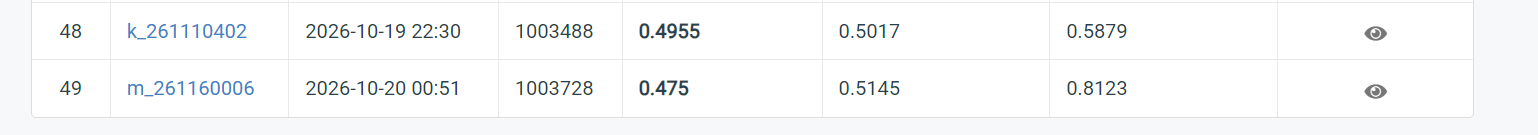

In [ ]:
!find /kaggle/input -name "*.pt"

In [ ]:
!pip install ijson
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # reduces fragmentation (the error message suggests it)
import os
import sys
import json
import math
import time
import random
import zipfile
from typing import List, Tuple, Dict, Any, Generator
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from tqdm.auto import tqdm
import numpy as np, ijson
from multiprocessing import Pool
import regex
!pip install -q scikit-learn pandas
!pip uninstall -y torchao

In [ ]:
HF_TOKEN = None
if "HF_TOKEN" in os.environ:
    HF_TOKEN = os.environ["HF_TOKEN"]
else:
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        HF_TOKEN = user_secrets.get_secret("HF")
        os.environ["HF_TOKEN"] = HF_TOKEN
        print("Successfully loaded HF_TOKEN from Kaggle Secrets.")
    except Exception as e:
        print(f"Note: Kaggle secrets not detected or HF key missing ({e}). Will attempt public access.")

if HF_TOKEN:
    try:
        from huggingface_hub import login
        login(token=HF_TOKEN)
        print("Huggingface hub authentication successful.")
    except Exception as err:
        print(f"HF Login warning: {err}")


print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device Count: {torch.cuda.device_count()}")
    for i in range(torch.cuda.device_count()):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
        
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

In [ ]:
# Config and paths
from huggingface_hub import HfApi

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = ["Phase_4_CJPE/Train/train.json", "Phase_4_CJPE/Train/dev.json"]
TEST_FILES  = ["Phase_4_CJPE/Test/test.json"]

VOCAB_SIZE = 33000
SEED = 67
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

SMOKE = False            # True = tiny end-to-end dry run (a few minutes) writing *_smoke outputs
SMOKE_STEPS = 6
USE_CKPT = True    # gradient checkpointing on the adapted layers: stores only layer inputs, recomputes the rest in backward

# ---- paths
OUTPUT_DIR = "/kaggle/working/cs781_phase4_v4" if os.path.exists("/kaggle") else "./outputs"
MODEL_PT   = "/kaggle/input/datasets/koooshiieee/phase2v4/final_model(2).pt"
TOK_DIR    = "/kaggle/working/tok_phase1"
TOK_REPO   = "DumbLad/legal-bpe-tokenizer-phase1-v2"
_sfx = "_smoke" if SMOKE else ""
CHECKPOINT_DIR  = os.path.join(OUTPUT_DIR, "model_checkpoint" + _sfx)
PREDICTION_PATH = os.path.join(OUTPUT_DIR, f"prediction{_sfx}.json")
SUBMISSION_ZIP  = os.path.join(OUTPUT_DIR, f"submission{_sfx}.zip")
LOSS_PLOT_PATH  = os.path.join(OUTPUT_DIR, f"training_curves{_sfx}.png")
TEST_PROBS_PATH = os.path.join(OUTPUT_DIR, f"test_probs{_sfx}.npy")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ---- data / chunking
LOWERCASE = True                       # dev/test are lower-cased; train has mixed case -> match them
CHUNK_LEN, OVERLAP, N_CHUNKS = 1024, 100, 6   # 5 chunks from the end + 1 head chunk
# HEAD_CH, TAIL_CH = 6000, 20000         # chars kept from the head/tail of very long docs before tokenising
MAX_CH = 150_000
HOLDOUT_DEV_FRAC = 0.5                 # share of dev (grouped by id) held out for threshold + checkpoint choice
DEV_REPEAT = 3                         # >1 upweights the remaining dev docs (closest in style to test)
NORMALIZE_WS = True                    # collapse all whitespace (dev/test have \n and double spaces, train doesn't)
CHUNK_MODE = "all"                     # all | tail1 | notail | head1

# ---- model / optimisation (BOT50: bottom 50% of layers frozen, top 50% fully fine-tuned)
BOT_PCT = 50
LR_HEAD, WD, WARMUP, DROPOUT = 1e-3, 0.05, 0.06, 0.2
BS_MICRO, ACCUM, EVAL_BS = 4, 4, 8     # micro-batch (docs), accumulation steps -> 16 docs per update
MAX_EPOCHS = 2
EVAL_EPOCH_FRAC = 0.14
TRAIN_BUDGET_SEC = 150 * 60


# ---- v3 head / schedule / selection flags
TOK_POOL = "lmam"                      # lm = [last;mean] (v2) | lmam = [last;mean;attn-pool;max-pool]
AGG = "xf1"                            # attn (v2) | xf1 | xf2 : chunk aggregator
D_CHUNK = 512                          # per-chunk projection width (lmam only)
CHUNK_DROP = 0.1                       # prob. of masking one random non-tail chunk per doc (train only)
SCHED = "inf_exp"                      # cosine | inf_exp
LR_PLATEAU = 0.3                       # inf_exp: LR multiplier reached after the decay phase
COOLDOWN_FRAC = 0.15                   # inf_exp: share of steps spent in the final cooldown
AVG_LAST_K = 3                         # average weights of the last K evals
SEL_METRIC = "f1"                     # auc | f1 | loss  (checkpoint selection)

# ---- v4: LoRMA+ on the top (100-BOT_PCT)% layers (replaces full fine-tuning)
LORMA_R, LORMA_ALPHA, LORMA_DROPOUT = 16, 32, 0.05              # same recipe as Phase-2 v4
LORMA_TARGETS = ("wq", "wo", "w_gate", "w_up", "w_down")        # Phase-2 targets minus the MLA-only names
LR_ADAPTER = 3e-4                                               # Phase-2 v4 adapter LR (5e-5 was a full-FT LR)
TRAIN_FINAL_NORM = False
# ---- v4: learned window selection
SEL_MODE = "auto"       # learned | tail  (tail = v3 behaviour, kept for A/B)
FORCE_TAIL = True          # always keep the window that ends at the end of the judgment
N_BUCKETS = 8              # relative-position buckets; chunk position embedding has N_BUCKETS+1 slots
N_POS = N_BUCKETS + 1
SELECTOR_FOLDS, SELECTOR_EPOCHS, SELECTOR_LR = 5, 6, 2e-3


assert CHUNK_MODE in ("all","tail1","notail","head1") and SEL_MODE in ("auto","learned","tail") and TOK_POOL in ("lm","lmam") \
   and AGG in ("attn","xf1","xf2") and SCHED in ("cosine","inf_exp") and SEL_METRIC in ("auc","f1","loss")


HF_OUT_REPO = "DumbLad/cs781-phase4-v4-cjpe"
if not SMOKE:
    HfApi(token=HF_TOKEN).create_repo(HF_OUT_REPO, repo_type="model", private=True, exist_ok=True)

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
from transformers import PreTrainedTokenizerFast
from huggingface_hub import hf_hub_download

def download_data():
    local_train_paths = []
    print("\nDownloading phase 4 training data.")
    for tf in TRAIN_FILES:
        try:
            p = hf_hub_download(repo_id = HF_DATASET_REPO, filename = tf, repo_type = "dataset", token = HF_TOKEN)
            local_train_paths.append(p)
            print(f"Downloaded: {tf}")
        except Exception as e:
            raise RuntimeError(f"Failed downloading training file {tf}: {e}") from e
            
    test_paths = []
    for tf in TEST_FILES:
        try:
            p = hf_hub_download(repo_id = HF_DATASET_REPO, filename = tf, repo_type = "dataset", token = HF_TOKEN)
            test_paths.append(p); print(f"Downloaded Test File: {tf}")
        except Exception as e:
            raise RuntimeError(f"Failed downloading test file {tf}: {e}") from e
    return local_train_paths, test_paths

In [ ]:
# List all files in the repository and filter for those containing "Phase_4"
all_files = HfApi(token=HF_TOKEN).list_repo_files(HF_DATASET_REPO, repo_type="dataset")
phase_4_files = [f for f in all_files if "Phase_4" in f]

print("Phase 4 files found:", phase_4_files)

# Then call your download function
train_paths, test_paths = download_data()
# inspect_json_files(train_paths, n=2)

In [ ]:
import os

# 1. Map filenames to their full local paths and set up test variables
P = {os.path.basename(p): p for p in train_paths}
TEST = test_paths

# 2. Assert that train.json and dev.json are present in train files, and exactly 1 test file exists
assert {"train.json", "dev.json"} <= set(P) and len(TEST) == 1, \
    f"Assertion failed! Found train files: {list(P.keys())}, Test files count: {len(TEST)}"

print(P.keys(), TEST)

In [ ]:
%%writefile bpe_tokenizer.py
#!/usr/bin/env python3
import os, json, regex
from typing import Dict, List, Tuple
from collections import Counter, defaultdict
from tqdm.auto import tqdm

import regex


_PAT = regex.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")


class PureByteLevelBPETokenizer:
    def __init__(self, vocab_size: int = 33000):
        self.vocab_size = vocab_size
        self.special_tokens = ["<pad>", "<unk>", "<s>", "</s>", "<mask>"]

        self.encoder: Dict[bytes, int] = {}
        self.decoder: Dict[int, bytes] = {}
        self.merges: Dict[Tuple[bytes, bytes], bytes] = {}       # pair -> merged token
        self.merge_ranks: Dict[Tuple[bytes, bytes], int] = {}    # pair -> order learned (lower = earlier)
        self._cache: Dict[str, List[int]] = {}

        self._init_base_vocab()

    def _init_base_vocab(self):
        for b in range(256):
            b_bytes = bytes([b])
            self.encoder[b_bytes] = b
            self.decoder[b] = b_bytes

        # special tokens
        for idx, token in enumerate(self.special_tokens, start=256):
            b_bytes = token.encode("utf-8")
            self.encoder[b_bytes] = idx
            self.decoder[idx] = b_bytes

    @property
    def pad_token_id(self) -> int:
        return self.encoder["<pad>".encode("utf-8")]

    @property
    def unk_token_id(self) -> int:
        return self.encoder["<unk>".encode("utf-8")]

    @property
    def bos_token_id(self) -> int:
        return self.encoder["<s>".encode("utf-8")]

    @property
    def eos_token_id(self) -> int:
        return self.encoder["</s>".encode("utf-8")]

    # ------------------------------------------------------------------ training
    @staticmethod
    def _merge_word(word, a, b, new):
        out, i, n = [], 0, len(word)
        while i < n:
            if i < n - 1 and word[i] == a and word[i + 1] == b:
                out.append(new)
                i += 2
            else:
                out.append(word[i])
                i += 1
        return out

    def train_from_texts(self, texts: List[str], target_vocab_size: int = None, min_word_freq: int = 2):
        if target_vocab_size is None:
            target_vocab_size = self.vocab_size
        num_merges = target_vocab_size - len(self.encoder)
        print(f"\nTraining byte level BPE from scratch. Target merges: {num_merges:,} | Base Vocab: {len(self.encoder)}")

        # 1) pre-tokenize + count unique words (the BPE then runs on this small table, not the raw text)
        word_counts = Counter()
        for text in tqdm(texts, desc="Counting pre-tokens"):
            if text and text.strip():
                word_counts.update(_PAT.findall(text))

        words, freqs = [], []
        for w, c in word_counts.items():
            if c >= min_word_freq:
                words.append([bytes([b]) for b in w.encode("utf-8", "replace")])
                freqs.append(c)
        del word_counts
        print(f"Unique words used for merge learning: {len(words):,}")

        # 2) initial pair statistics (updated incrementally afterwards)
        pair_counts = defaultdict(int)
        where = defaultdict(set)
        for i, w in enumerate(tqdm(words, desc="Initial pair counts")):
            for p in zip(w, w[1:]):
                pair_counts[p] += freqs[i]
                where[p].add(i)

        # 3) merge loop
        pbar = tqdm(total=num_merges, desc="Learning BPE Merges", dynamic_ncols=True)
        for _ in range(num_merges):
            if not pair_counts:
                print("No more candidate pairs found to merge.")
                break

            best_pair, freq = max(pair_counts.items(), key=lambda kv: kv[1])
            if freq < 2:
                print(f"Stopping early: Most frequent pair frequency is {freq}")
                break

            a, b = best_pair
            merged_token = a + b
            self.merges[best_pair] = merged_token
            self.merge_ranks[best_pair] = len(self.merge_ranks)
            if merged_token not in self.encoder:          # two merge paths can give the same bytes
                new_id = len(self.encoder)
                self.encoder[merged_token] = new_id
                self.decoder[new_id] = merged_token

            for i in list(where[best_pair]):
                w, f = words[i], freqs[i]
                for p in zip(w, w[1:]):
                    pair_counts[p] -= f
                    if pair_counts[p] <= 0:
                        del pair_counts[p]
                w = self._merge_word(w, a, b, merged_token)
                words[i] = w
                for p in zip(w, w[1:]):
                    pair_counts[p] += f
                    where[p].add(i)
            del where[best_pair]
            pair_counts.pop(best_pair, None)

            pbar.update(1)
            pbar.set_postfix({"vocab_size": len(self.encoder), "top_pair_freq": freq})

        pbar.close()
        self._cache.clear()
        print(f"Training finished! Final Vocab Size: {len(self.encoder):,}")

    # ------------------------------------------------------------------ encode / decode
    def _encode_word(self, word: str) -> List[int]:
        cached = self._cache.get(word)
        if cached is not None:
            return cached
        tokens = [bytes([b]) for b in word.encode("utf-8", "replace")]
        while len(tokens) >= 2:
            best_pair, best_rank = None, None
            for p in zip(tokens, tokens[1:]):
                r = self.merge_ranks.get(p)
                if r is not None and (best_rank is None or r < best_rank):
                    best_pair, best_rank = p, r
            if best_pair is None:
                break
            tokens = self._merge_word(tokens, best_pair[0], best_pair[1], self.merges[best_pair])
        ids = [self.encoder.get(t, self.unk_token_id) for t in tokens]
        if len(self._cache) < 1_000_000:
            self._cache[word] = ids
        return ids

    def encode(self, text: str) -> List[int]:
        ids: List[int] = []
        for word in _PAT.findall(text):
            ids.extend(self._encode_word(word))
        return ids

    def decode(self, token_ids: List[int]) -> str:
        raw_bytes = b"".join(self.decoder.get(i, b"<unk>") for i in token_ids)
        return raw_bytes.decode("utf-8", errors="replace")

    # ------------------------------------------------------------------ save / load
    def save(self, save_dir: str):
        os.makedirs(save_dir, exist_ok=True)
        vocab_path = os.path.join(save_dir, "vocab.json")
        merges_path = os.path.join(save_dir, "merges.json")
        config_path = os.path.join(save_dir, "tokenizer_config.json")

        # latin1 maps bytes 1:1 onto code points, so any byte string survives JSON
        ser_vocab = {k.decode("latin1"): v for k, v in self.encoder.items()}
        with open(vocab_path, "w", encoding="utf-8") as f:
            json.dump(ser_vocab, f, ensure_ascii=False, indent=2)

        # JSON (not a space-separated text file): tokens can contain spaces, newlines, \r, \xa0 ...
        ser_merges = [[p1.decode("latin1"), p2.decode("latin1")] for (p1, p2) in self.merges]  # in learned order
        with open(merges_path, "w", encoding="utf-8") as f:
            json.dump(ser_merges, f, ensure_ascii=False)

        config = {
            "tokenizer_class": "PureByteLevelBPETokenizer",
            "vocab_size": len(self.encoder),
            "special_tokens": self.special_tokens,
            "pad_token_id": self.pad_token_id,
            "bos_token_id": self.bos_token_id,
            "eos_token_id": self.eos_token_id
        }
        with open(config_path, "w", encoding="utf-8") as f:
            json.dump(config, f, indent=2)

        print(f"Tokenizer saved successfully to {save_dir}")

    @classmethod
    def load(cls, save_dir: str) -> "PureByteLevelBPETokenizer":
        tok = cls()
        with open(os.path.join(save_dir, "vocab.json"), "r", encoding="utf-8") as f:
            ser_vocab = json.load(f)
        tok.encoder = {k.encode("latin1"): v for k, v in ser_vocab.items()}
        tok.decoder = {v: k.encode("latin1") for k, v in ser_vocab.items()}

        tok.merges, tok.merge_ranks = {}, {}
        with open(os.path.join(save_dir, "merges.json"), "r", encoding="utf-8") as f:
            for rank, (s1, s2) in enumerate(json.load(f)):
                p1, p2 = s1.encode("latin1"), s2.encode("latin1")
                tok.merges[(p1, p2)] = p1 + p2
                tok.merge_ranks[(p1, p2)] = rank
        return tok


In [ ]:
# ---- v4: LoRMA+ :  h = (I + s*B@A) W x   (B = 0 at init -> step 0 == base model)
import torch.nn as nn, torch.nn.functional as F
class LoRMAPlusLinear(nn.Module):
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        self.base, self.scale = base, alpha / r
        w = base.weight
        self.A = nn.Parameter(torch.empty(r, base.out_features, device=w.device, dtype=w.dtype))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=w.device, dtype=w.dtype))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
    def forward(self, x):
        h = self.base(x)
        return h + F.linear(F.linear(self.drop(h), self.A), self.B) * self.scale
    @torch.no_grad()
    def merge(self):
        self.base.weight += (self.B @ (self.A @ self.base.weight)) * self.scale
        self.B.zero_()

def apply_lorma_plus(base, targets, r, alpha, dropout, layer_ids):
    n = 0
    for i, blk in enumerate(base.layers):
        if i not in layer_ids: continue
        for mod in (blk.attn, blk.mlp):
            for name in targets:
                lin = getattr(mod, name, None)
                if isinstance(lin, nn.Linear): setattr(mod, name, LoRMAPlusLinear(lin, r, alpha, dropout)); n += 1
    return n

In [ ]:
%%writefile llama_scratch.py
"""
Optimized Modern Legal LLM (from scratch):
- Pre-norm RMSNorm
- QK-Norm (RMSNorm on Query and Key vectors before attention)
- Rotary Position Embeddings (RoPE)
- Grouped Query Attention (GQA) with fused SDPA
- Parallel Attention & SwiGLU FFN (PaLM / GPT-J style)
- Deep & Narrow parameter presets (MobileLLM efficiency)
- Tied input/output embeddings
"""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F

# ----------------------------------------------------------------------------- Config
@dataclass
class Config:
    vocab_size: int = 33000
    d_model: int = 672
    n_layers: int = 18
    n_heads: int = 14
    n_kv_heads: int = 2          # 14 query heads share 2 KV heads (7:1 GQA)
    ffn_hidden: int = 1792
    max_seq_len: int = 1280
    rope_cache_len: int = 4096
    rope_theta: float = 10000.0
    norm_eps: float = 1e-5
    tie_embeddings: bool = True
    pos_enc: str = "rope"        # "rope"
    attn_type: str = "gqa"       # "gqa"
    attn_impl: str = "sdpa"      # "sdpa" (PyTorch fused kernel)
    use_qk_norm: bool = True     # QK-Norm for training stability
    parallel_attn: bool = True   # Parallel Attention + FFN

PRESETS = {
    "deep_narrow_120m": dict(d_model=640, n_layers=20, n_heads=10, n_kv_heads=2, ffn_hidden=1664),
    "arch_deep_narrow_135m": dict(d_model=672, n_layers=18, n_heads=14, n_kv_heads=2, ffn_hidden=1792),
    "tiny": dict(d_model=64, n_layers=2, n_heads=4, n_kv_heads=2, ffn_hidden=128),
}

def count_params(model, verbose=True) -> int:
    total = sum(p.numel() for p in model.parameters())
    if verbose:
        emb = model.tok_emb.weight.numel()
        blocks = sum(p.numel() for p in model.layers.parameters())
        print(f"Total: {total/1e6:.2f}M | Transformer Blocks: {blocks/1e6:.2f}M | Embeddings: {emb/1e6:.2f}M")
    return total

# ----------------------------------------------------------------------------- RMSNorm
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)

# ----------------------------------------------------------------------------- RoPE
def build_rope_cache(head_dim, max_len, theta):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))
    t = torch.arange(max_len).float()
    freqs = torch.outer(t, inv_freq)
    return freqs.cos(), freqs.sin()

def apply_rope(x, cos, sin):
    half = x.shape[-1] // 2
    xf = x.float()
    x1, x2 = xf[..., :half], xf[..., half:]
    cos = cos[None, None]
    sin = sin[None, None]
    out = torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.type_as(x)

# ----------------------------------------------------------------------------- GQA Attention with QK-Norm
def repeat_kv(x, n_rep):
    if n_rep == 1:
        return x
    B, n_kv, S, hd = x.shape
    return x[:, :, None].expand(B, n_kv, n_rep, S, hd).reshape(B, n_kv * n_rep, S, hd)

class GQAttention(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        assert cfg.d_model % cfg.n_heads == 0 and cfg.n_heads % cfg.n_kv_heads == 0
        self.nh = cfg.n_heads
        self.nkv = cfg.n_kv_heads
        self.hd = cfg.d_model // cfg.n_heads
        self.n_rep = self.nh // self.nkv
        self.impl = cfg.attn_impl
        self.use_qk_norm = cfg.use_qk_norm

        self.wq = nn.Linear(cfg.d_model, self.nh * self.hd, bias=False)
        self.wk = nn.Linear(cfg.d_model, self.nkv * self.hd, bias=False)
        self.wv = nn.Linear(cfg.d_model, self.nkv * self.hd, bias=False)
        self.wo = nn.Linear(self.nh * self.hd, cfg.d_model, bias=False)

        if self.use_qk_norm:
            self.q_norm = RMSNorm(self.hd, cfg.norm_eps)
            self.k_norm = RMSNorm(self.hd, cfg.norm_eps)

    def forward(self, x, cos, sin, key_valid=None, past=None, use_cache=False):
        B, T, _ = x.shape
        q = self.wq(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        k = self.wk(x).view(B, T, self.nkv, self.hd).transpose(1, 2)
        v = self.wv(x).view(B, T, self.nkv, self.hd).transpose(1, 2)

        # Apply QK-Norm
        if self.use_qk_norm:
            q = self.q_norm(q)
            k = self.k_norm(k)

        # Apply RoPE
        if cos is not None:
            q = apply_rope(q, cos, sin)
            k = apply_rope(k, cos, sin)

        if past is not None:
            k = torch.cat([past[0], k], dim=2)
            v = torch.cat([past[1], v], dim=2)
        new_cache = (k, v) if use_cache else None
        S = k.shape[2]

        k = repeat_kv(k, self.n_rep)
        v = repeat_kv(v, self.n_rep)

        if self.impl == "sdpa" and key_valid is None and T == S:
            out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            qpos = torch.arange(S - T, S, device=x.device)
            kpos = torch.arange(S, device=x.device)
            rel = qpos[:, None] - kpos[None, :]
            allowed = (rel >= 0)[None, None]
            if key_valid is not None:
                allowed = allowed & key_valid[:, None, None, :]
            scores = ((q * (self.hd ** -0.5)) @ k.transpose(-2, -1)).float()
            scores = scores.masked_fill(~allowed, -1e30)
            probs = torch.softmax(scores, dim=-1).to(v.dtype)
            out = probs @ v

        out = out.transpose(1, 2).reshape(B, T, self.nh * self.hd)
        return self.wo(out), new_cache

# ----------------------------------------------------------------------------- SwiGLU FFN
class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden):
        super().__init__()
        self.w_gate = nn.Linear(d_model, hidden, bias=False)
        self.w_up = nn.Linear(d_model, hidden, bias=False)
        self.w_down = nn.Linear(hidden, d_model, bias=False)

    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))

# ----------------------------------------------------------------------------- Transformer Block
class Block(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.parallel_attn = cfg.parallel_attn
        self.attn_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.attn = GQAttention(cfg)
        self.mlp_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.mlp = SwiGLU(cfg.d_model, cfg.ffn_hidden)

    def forward(self, x, cos, sin, key_valid=None, past=None, use_cache=False):
        if self.parallel_attn:
            # Parallel Attention & FFN (PaLM style)
            h_attn, new_cache = self.attn(self.attn_norm(x), cos, sin, key_valid, past, use_cache)
            h_mlp = self.mlp(self.mlp_norm(x))
            x = x + h_attn + h_mlp
        else:
            h, new_cache = self.attn(self.attn_norm(x), cos, sin, key_valid, past, use_cache)
            x = x + h
            x = x + self.mlp(self.mlp_norm(x))
        return x, new_cache

# ----------------------------------------------------------------------------- Full LM
class LlamaLM(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.layers = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)

        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        cos, sin = build_rope_cache(cfg.d_model // cfg.n_heads, cfg.rope_cache_len, cfg.rope_theta)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("wo.weight") or name.endswith("w_down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, use_cache=False, cache=None, start_pos=0,
                key_valid=None, all_logits=False):
        B, T = idx.shape
        x = self.tok_emb(idx)
        cos = self.rope_cos[start_pos:start_pos + T]
        sin = self.rope_sin[start_pos:start_pos + T]

        new_caches = []
        for i, layer in enumerate(self.layers):
            past = cache[i] if cache is not None else None
            x, c = layer(x, cos, sin, key_valid=key_valid, past=past, use_cache=use_cache)
            new_caches.append(c)
        x = self.norm(x)

        if targets is not None:
            logits = self.lm_head(x)
            return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
        logits = self.lm_head(x if all_logits else x[:, -1:, :])
        return logits, (new_caches if use_cache else None)

# ----------------------------------------------------------------------------- Generation
@torch.no_grad()
def generate(model, prompts, max_new_tokens, eos_id, pad_id, temperature=0.2, top_k=0,
             top_p=0.9, rep_penalty=1.12, ban_eos=False):
    model.eval()
    device = next(model.parameters()).device
    V = model.cfg.vocab_size
    B = len(prompts)
    L = max(len(p) for p in prompts)
    ids = torch.full((B, L), pad_id, dtype=torch.long, device=device)
    key_valid = torch.zeros(B, L, dtype=torch.bool, device=device)
    seen = torch.zeros(B, V, dtype=torch.bool, device=device)

    for b, p in enumerate(prompts):
        t = torch.tensor(p, dtype=torch.long, device=device)
        ids[b, L - len(p):] = t
        key_valid[b, L - len(p):] = True
        seen[b, t] = True

    out = [[] for _ in range(B)]
    finished = torch.zeros(B, dtype=torch.bool, device=device)
    amp = torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda"))

    with amp:
        logits, cache = model(ids, use_cache=True, key_valid=key_valid, start_pos=0)
        for step in range(max_new_tokens):
            lg = logits[:, -1, :].float()
            if ban_eos:
                lg[:, eos_id] = float("-inf")
            if rep_penalty != 1.0:
                pen = torch.where(lg > 0, lg / rep_penalty, lg * rep_penalty)
                lg = torch.where(seen, pen, lg)

            if temperature <= 0.05:
                nxt = lg.argmax(-1)
            else:
                lg = lg / temperature
                if top_k and top_k > 0:
                    kth = torch.topk(lg, min(top_k, V)).values[:, -1:]
                    lg = lg.masked_fill(lg < kth, float("-inf"))
                if top_p < 1.0:
                    sl, si = torch.sort(lg, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    drop = (pr.cumsum(-1) - pr) > top_p
                    sl = sl.masked_fill(drop, float("-inf"))
                    lg = torch.full_like(lg, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(lg, dim=-1), 1).squeeze(1)

            nxt = torch.where(finished, torch.full_like(nxt, pad_id), nxt)
            for b in range(B):
                if not finished[b] and nxt[b].item() != eos_id:
                    out[b].append(int(nxt[b].item()))
            finished = finished | (nxt == eos_id)
            seen.scatter_(1, nxt[:, None], True)
            if bool(finished.all()):
                break
            key_valid = torch.cat([key_valid, torch.ones(B, 1, dtype=torch.bool, device=device)], dim=1)
            logits, cache = model(nxt[:, None], use_cache=True, cache=cache,
                                  start_pos=L + step, key_valid=key_valid)
    return out

In [ ]:
from huggingface_hub import hf_hub_download
for f in ["vocab.json","merges.json","tokenizer_config.json"]:
    hf_hub_download("DumbLad/legal-bpe-tokenizer-phase1-v2", f, repo_type="model",
                    local_dir=TOK_DIR, token=HF_TOKEN)

In [ ]:
import os
import json
import ijson
import numpy as np
from collections import Counter

# Use the paths your previous notebook cells already downloaded.
TRAIN_PATH = P["train.json"]
DEV_PATH   = P["dev.json"]
TEST_PATH  = TEST[0]

def audit_json_array(path, name, show_samples=3):
    label_counts = Counter()
    lengths = []
    ids = set()
    duplicate_ids = 0
    missing_id = 0
    missing_text = 0
    missing_label = 0
    empty_text = 0
    samples = []

    print(f"\n{'='*65}\n{name}: {os.path.basename(path)}")
    print(f"File size: {os.path.getsize(path) / (1024**2):.2f} MiB")

    with open(path, "rb") as f:
        for record in ijson.items(f, "item"):
            record_id = record.get("id")
            text = record.get("text")
            label = record.get("label")

            if record_id is None:
                missing_id += 1
            elif record_id in ids:
                duplicate_ids += 1
            else:
                ids.add(record_id)

            if text is None:
                missing_text += 1
                text = ""
            text = str(text)
            lengths.append(len(text))

            if not text.strip():
                empty_text += 1

            if label is None:
                missing_label += 1
            else:
                # Keep the original label value for now; inspect unexpected values.
                label_counts[str(label)] += 1

            if len(samples) < show_samples:
                samples.append({
                    "id": record_id,
                    "label": label,
                    "text_preview": text[:250]
                })

    lengths = np.asarray(lengths, dtype=np.int64)
    print("Records:", len(lengths))
    print("Label counts:", dict(label_counts))
    if len(lengths):
        print("Label proportions:",
              {k: round(v / len(lengths), 4)
               for k, v in label_counts.items()})
        print("Text length in characters:")
        for q in [0, 25, 50, 75, 90, 95, 99, 100]:
            print(f"  P{q:02}: {np.percentile(lengths, q):,.0f}")
    print("Missing IDs:", missing_id)
    print("Duplicate IDs:", duplicate_ids)
    print("Missing text fields:", missing_text)
    print("Empty/whitespace-only texts:", empty_text)
    print("Missing labels:", missing_label)
    print("Sample records:")
    for s in samples:
        print(json.dumps(s, ensure_ascii=False, indent=2))

    return {
        "ids": ids,
        "labels": label_counts,
        "count": len(lengths),
        "lengths": lengths
    }

train_audit = audit_json_array(TRAIN_PATH, "TRAIN")
dev_audit   = audit_json_array(DEV_PATH, "DEV / VALIDATION")
test_audit  = audit_json_array(TEST_PATH, "TEST")
print("\nTrain/dev ID overlap:",
      len(train_audit["ids"] & dev_audit["ids"]))
print("Train/test ID overlap:",
      len(train_audit["ids"] & test_audit["ids"]))
print("Dev/test ID overlap:",
      len(dev_audit["ids"] & test_audit["ids"]))

In [ ]:
# Load train/dev/test (streaming), dedupe, build the dev holdout
import hashlib, re
from collections import defaultdict

def _trunc(text):
    if NORMALIZE_WS: text = re.sub(r"\s+", " ", text).strip()
    if len(text) <= MAX_CH: return text
    return text[:MAX_CH // 5] + " " + text[-(MAX_CH * 4 // 5):]    # only absurdly long docs are cut (20% head / 80% tail)

def load_split(path, with_label):
    recs = []
    with open(path, "rb") as f:
        for r in tqdm(ijson.items(f, "item"), desc=os.path.basename(path)):
            text = str(r.get("text") or "")
            recs.append(dict(
                id=r["id"],
                label=int(r["label"]) if with_label else None,   # test labels are never read
                md5=hashlib.md5(text.encode("utf-8", "ignore")).hexdigest(),
                n_chars=len(text),
                has_upper=any(c.isupper() for c in text[:3000]),
                text=_trunc(text)))
    return recs

def dedupe(recs, name):
    groups = defaultdict(list)
    for r in recs: groups[r["md5"]].append(r)
    keep, n_dup, n_conf = [], 0, 0
    for g in groups.values():
        n_dup += len(g) - 1
        if len({x["label"] for x in g}) > 1:           # same text, different labels -> ambiguous, drop
            n_conf += len(g); continue
        keep.append(g[0])
    print(f"{name}: {len(recs)} -> {len(keep)} | duplicate copies: {n_dup} | dropped (conflicting labels): {n_conf}")
    return keep

train = dedupe(load_split(P["train.json"], True), "train")
dev   = dedupe(load_split(P["dev.json"],   True), "dev")
test_recs = load_split(TEST[0], False)                 # keep EVERY test record, in file order
assert len({r["id"] for r in test_recs}) == len(test_recs), "duplicate ids in test.json"

# remove cross-split text overlap (never train on dev/test text)
test_md5 = {r["md5"] for r in test_recs}
n0 = len(dev);   dev = [r for r in dev if r["md5"] not in test_md5];   print("dev docs also in test removed:", n0 - len(dev))
dev_md5 = {r["md5"] for r in dev}
n0 = len(train); train = [r for r in train if r["md5"] not in test_md5 and r["md5"] not in dev_md5]
print("train docs also in dev/test removed:", n0 - len(train))

# holdout = share of dev, grouped by id (dev is closest in style to test, and balanced)
ids = sorted({r["id"] for r in dev}); random.Random(SEED).shuffle(ids)
hold_ids  = set(ids[: int(len(ids) * HOLDOUT_DEV_FRAC)])
hold      = [r for r in dev if r["id"] in hold_ids]
dev_train = [r for r in dev if r["id"] not in hold_ids]

if SMOKE:
    train, dev_train, hold, test_recs = train[:300], dev_train[:40], hold[:60], test_recs[:16]

def _stats(name, recs):
    n = len(recs)
    pos = f"{np.mean([r['label'] for r in recs]):.3f}" if recs and recs[0]["label"] is not None else "n/a"
    print(f"{name:10s} n={n:6d} | pos rate {pos} | mixed-case share {np.mean([r['has_upper'] for r in recs]):.3f} "
          f"| median chars {np.median([r['n_chars'] for r in recs]):,.0f}")
for nm, rs in [("train", train), ("dev_train", dev_train), ("holdout", hold), ("test", test_recs)]: _stats(nm, rs)
c = Counter(r["id"] for r in train)
print("train ids shared by >1 distinct doc:", sum(v > 1 for v in c.values()))

In [ ]:
# Tokenise WHOLE judgments; window selection happens in the next cell
import multiprocessing as mp
from bpe_tokenizer import PureByteLevelBPETokenizer
STRIDE = CHUNK_LEN - OVERLAP
_TOK = None
def _init_worker():
    global _TOK
    _TOK = PureByteLevelBPETokenizer.load(TOK_DIR)
def _tok_job(text):
    ids = _TOK.encode(text.lower() if LOWERCASE else text) or [_TOK.unk_token_id]
    return np.asarray(ids, dtype=np.uint16)
def tokenize_docs(recs, desc):
    with mp.get_context("fork").Pool(min(4, os.cpu_count() or 1), initializer=_init_worker) as pool:
        ids = list(tqdm(pool.imap(_tok_job, [r["text"] for r in recs], chunksize=16), total=len(recs), desc=desc))
    return [dict(id=r["id"], label=r["label"], ids=a) for r, a in zip(recs, ids)]

def cand_windows(n):            # every window, counted backwards from the last token; wins[0] = tail window
    out, end = [], n
    while True:
        start = max(0, end - CHUNK_LEN); out.append((start, end))
        if start == 0: out[-1] = (0, min(n, CHUNK_LEN)); break      # head window always full length (= v3's head chunk)
        end -= STRIDE
    return out

t0 = time.time()
train_docs     = tokenize_docs(train,     "train")
dev_train_docs = tokenize_docs(dev_train, "dev (train part)")
hold_docs      = tokenize_docs(hold,      "dev (holdout)")
test_docs      = tokenize_docs(test_recs, "test")
print(f"tokenised in {(time.time()-t0)/60:.1f} min")
for nm, ds in [("train", train_docs), ("holdout", hold_docs), ("test", test_docs)]:
    nt = [len(d["ids"]) for d in ds]
    print(f"{nm:8s} docs={len(ds):6d} | mean tokens/doc {np.mean(nt):7.0f} | P99 {np.percentile(nt,99):7.0f}")
assert max(int(d["ids"].max()) for d in train_docs[:2000]) < VOCAB_SIZE

In [ ]:
# ---- v4: learn WHICH windows to keep (cross-fitted attention-MIL over cheap window descriptors)
from sklearn.metrics import roc_auc_score
E_gpu = torch.load(MODEL_PT, map_location="cpu", weights_only=False)["model"]["tok_emb.weight"].float().to(device)
D_E = E_gpu.shape[1]

def pos_bucket(i, a, b, n):
    return 0 if i == 0 else 1 + min(N_BUCKETS - 1, int((a + b) / 2 / max(n, 1) * N_BUCKETS))

@torch.no_grad()
def describe(d):
    ids = torch.from_numpy(d["ids"].astype(np.int64)).to(device); n = len(ids)
    wins = cand_windows(n)
    cs = torch.cat([torch.zeros(1, D_E, device=device), E_gpu[ids].cumsum(0)])      # prefix sums -> window means
    a = torch.tensor([w[0] for w in wins], device=device); b = torch.tensor([w[1] for w in wins], device=device)
    mean = (cs[b] - cs[a]) / (b - a)[:, None].float()
    desc = torch.cat([mean, (torch.log1p((b - a).float()) / 7)[:, None]], 1)
    d["wins"], d["desc"] = wins, desc.half().cpu()
    d["bucket"] = np.array([pos_bucket(i, x, y, n) for i, (x, y) in enumerate(wins)], dtype=np.int64)

class Selector(nn.Module):
    def __init__(self, d_in, d=128):
        super().__init__()
        self.f = nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, d), nn.GELU(), nn.Dropout(0.2))
        self.pos = nn.Embedding(N_BUCKETS + 1, d)
        self.a1, self.a2 = nn.Linear(d, d // 2), nn.Linear(d // 2, 1, bias=False)
        self.out = nn.Linear(d, 1)
    def scores(self, x, bucket):
        h = self.f(x) + self.pos(bucket)
        return h, self.a2(torch.tanh(self.a1(h))).squeeze(-1)
    def forward(self, x, bucket, mask):
        h, s = self.scores(x, bucket); s = s.masked_fill(~mask, float("-inf"))
        return self.out((torch.softmax(s, 1).unsqueeze(-1) * h).sum(1)).squeeze(-1)

def _pad(docs):
    S = max(len(d["desc"]) for d in docs)
    X = torch.zeros(len(docs), S, D_E + 1); Bk = torch.zeros(len(docs), S, dtype=torch.long); M = torch.zeros(len(docs), S, dtype=torch.bool)
    for i, d in enumerate(docs):
        s = len(d["desc"]); X[i, :s] = d["desc"].float(); Bk[i, :s] = torch.as_tensor(d["bucket"]); M[i, :s] = True
    return X.to(device), Bk.to(device), M.to(device)

def fit_selector(docs, epochs, bs=64):
    net = Selector(D_E + 1).to(device); opt = torch.optim.AdamW(net.parameters(), SELECTOR_LR, weight_decay=0.05)
    y = torch.tensor([d["label"] for d in docs], dtype=torch.float32)
    for ep in range(epochs):
        net.train(); perm = np.random.permutation(len(docs))
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; X, Bk, M = _pad([docs[j] for j in idx])
            loss = F.binary_cross_entropy_with_logits(net(X, Bk, M), y[idx].to(device))
            opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

@torch.no_grad()
def window_scores(net, docs, bs=128):
    out = []
    for i in range(0, len(docs), bs):
        chunk = docs[i:i + bs]; X, Bk, _ = _pad(chunk); _, s = net.scores(X, Bk)
        out += [s[j, :len(d["desc"])].float().cpu().numpy() for j, d in enumerate(chunk)]
    return out

def tail_heavy_idx(S):                                   # v3 behaviour: last 5 windows + head window
    return list(range(S)) if S <= N_CHUNKS else list(range(N_CHUNKS - 1)) + [S - 1]

def pick_windows(scores, K=N_CHUNKS, force_tail=None):
    force_tail = FORCE_TAIL if force_tail is None else force_tail
    S = len(scores)
    if S <= K: return list(range(S))
    s = np.array(scores, dtype=np.float64); keep = []
    if force_tail: keep, s[0] = [0], -np.inf
    keep += [int(i) for i in np.argsort(-s)[:K - len(keep)]]
    return sorted(keep)

all_docs = train_docs + dev_train_docs + hold_docs + test_docs
for d in tqdm(all_docs, desc="describe windows"): describe(d)

sel_train = train_docs + dev_train_docs                  # unique docs only (no DEV_REPEAT copies)
K_F = 2 if SMOKE else SELECTOR_FOLDS
fold = np.random.RandomState(SEED).randint(0, K_F, len(sel_train))
nets = []
for k in range(K_F):
    net_k = fit_selector([d for d, f in zip(sel_train, fold) if f != k], 1 if SMOKE else SELECTOR_EPOCHS)
    oof = [d for d, f in zip(sel_train, fold) if f == k]
    for d, s in zip(oof, window_scores(net_k, oof)): d["scores"] = s          # out-of-fold scores
    nets.append(net_k); print(f"selector fold {k+1}/{K_F} done", flush=True)
for ds in (hold_docs, test_docs):
    allsc = [window_scores(n_, ds) for n_ in nets]
    for j, d in enumerate(ds): d["scores"] = np.mean([sc[j] for sc in allsc], 0)
torch.save([n_.state_dict() for n_ in nets], os.path.join(CHECKPOINT_DIR, "selector.pt"))

@torch.no_grad()
def proxy_auc(docs, choose):          # free go/no-go: how well do the selector nets predict from ONLY the chosen windows?
    p = np.zeros(len(docs))
    for i, d in enumerate(docs):
        idx = choose(d); X, Bk, M = _pad([dict(desc=d["desc"][idx], bucket=d["bucket"][idx])])
        p[i] = np.mean([torch.sigmoid(n_(X, Bk, M)).item() for n_ in nets])
    y = [d["label"] for d in docs]
    return roc_auc_score(y, p) if len(set(y)) > 1 else float("nan")
variants = {"tail":   lambda d: tail_heavy_idx(len(d["wins"])),
            "forced": lambda d: pick_windows(d["scores"], force_tail=True),
            "free":   lambda d: pick_windows(d["scores"], force_tail=False)}
proxy = {k: proxy_auc(hold_docs, f) for k, f in variants.items()}
proxy["all windows"] = proxy_auc(hold_docs, lambda d: list(range(len(d["wins"]))))
print("holdout proxy AUC:", {k: round(v, 4) for k, v in proxy.items()})
if SEL_MODE == "auto":
    SEL_CHOICE = "tail"
    for k in ("forced", "free"):                    # a learned variant must beat the current pick by a margin
        if proxy[k] > proxy[SEL_CHOICE] + 0.005: SEL_CHOICE = k
elif SEL_MODE == "tail": SEL_CHOICE = "tail"
else: SEL_CHOICE = "forced" if FORCE_TAIL else "free"
print("window selection used:", SEL_CHOICE)

def build_chunks(d):
    S = len(d["wins"])
    idx = tail_heavy_idx(S) if SEL_CHOICE == "tail" else pick_windows(d["scores"], force_tail=(SEL_CHOICE == "forced"))
    order = sorted(idx, key=lambda i: (int(d["bucket"][i]), i))
    d["chunks"] = [d["ids"][d["wins"][i][0]:d["wins"][i][1]].copy() for i in order]
    d["pos"]    = [int(d["bucket"][i]) for i in order]
    d["starts"] = [d["wins"][i][0] for i in order]
for d in all_docs:
    build_chunks(d); d["ids"] = d["desc"] = d["scores"] = None
cnt = np.bincount([p for d in train_docs for p in d["pos"]], minlength=N_BUCKETS + 1)
print("share of kept windows per position bucket (0 = tail window):", np.round(cnt / cnt.sum(), 3))

In [ ]:
# Load the Phase-2-v4 LM, sanity-check it, build the BOT50 classifier
sys.path.insert(0, os.getcwd())
from llama_scratch import Config, LlamaLM

tok = PureByteLevelBPETokenizer.load(TOK_DIR)
PAD = tok.pad_token_id
assert torch.cuda.is_available() or SMOKE, "GPU required"
ck = torch.load(MODEL_PT, map_location="cpu", weights_only=False)
cfg = Config(**ck["cfg"]); cfg.attn_impl = "sdpa"

print("ckpt file mtime:", time.ctime(os.path.getmtime(MODEL_PT)), "| size MB:", os.path.getsize(MODEL_PT)//2**20)
print("ckpt step/val:", ck.get("step"), ck.get("val"), "| cfg:", ck["cfg"])
base = LlamaLM(cfg); base.load_state_dict(ck["model"]); del ck
base = base.to(device).eval()
print(f"layers={cfg.n_layers} d_model={cfg.d_model} pos_enc={cfg.pos_enc} max_seq_len={cfg.max_seq_len} "
      f"vocab(model)={cfg.vocab_size} vocab(tokenizer)={len(tok.encoder)}")
assert len(tok.encoder) <= cfg.vocab_size, "tokenizer vocab larger than model vocab"
if CHUNK_LEN > cfg.max_seq_len: print(f"WARNING: CHUNK_LEN {CHUNK_LEN} > trained context {cfg.max_seq_len}")

# --- sanity 1: tokenizer round trip on short raw docs
full = [r["text"] for r in train + hold if isinstance(r["text"], str) and len(r["text"]) < 20000][:20]
bad = sum(tok.decode(tok.encode(t)) != t for t in full)
print(f"tokenizer round-trip failures: {bad}/{len(full)}")

# --- sanity 2: LM next-token loss (Phase-1 val loss was ~2-2.5; > 5 means wrong tokenizer/checkpoint)
@torch.no_grad()
def lm_loss(ids):
    if len(ids) < 8: return float("nan")
    x = torch.tensor([ids[:-1]], device=device); y = torch.tensor([ids[1:]], device=device)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        return base(x, targets=y).item()
hold_l = [lm_loss(d["chunks"][0][:512].astype(np.int64).tolist()) for d in hold_docs[:8]]
print(f"LM loss on holdout chunks (dev style, {'lower-cased' if LOWERCASE else 'raw'}): {np.nanmean(hold_l):.3f}")
mixed = [r for r in train if r["has_upper"]][:8]
def _head(r): return (r["text"][0] if isinstance(r["text"], tuple) else r["text"])[:2000]
if mixed:
    raw = np.nanmean([lm_loss(tok.encode(_head(r))[:512]) for r in mixed])
    low = np.nanmean([lm_loss(tok.encode(_head(r).lower())[:512]) for r in mixed])
    print(f"LM loss on mixed-case train docs: raw {raw:.3f} vs lower-cased {low:.3f}")
assert np.nanmean(hold_l) < 5.0, "LM loss too high: wrong tokenizer or checkpoint"
for lst in (train, dev_train, hold, test_recs):        # free the raw text
    for r in lst: r["text"] = None

# --- BOT50 classifier
class CJPEModel(nn.Module):
    def __init__(self, base, n_frozen, n_pos, dropout=0.1):
        super().__init__()
        self.base, self.n_frozen = base, n_frozen
        d = base.cfg.d_model
        self.tok_pool, self.agg, self.chunk_drop = TOK_POOL, AGG, CHUNK_DROP
        if TOK_POOL == "lmam":
            self.tok_att = nn.Linear(d, 1)                       # learned attention pool over tokens
            self.proj = nn.Sequential(nn.Linear(4 * d, D_CHUNK), nn.GELU(), nn.Dropout(dropout), nn.LayerNorm(D_CHUNK))
            Dh = D_CHUNK
        else:
            self.ln = nn.LayerNorm(2 * d); Dh = 2 * d             # v2 path
        self.pos_emb = nn.Embedding(n_pos, Dh)
        if AGG in ("xf1", "xf2"):
            lyr = nn.TransformerEncoderLayer(Dh, 8, 1024, dropout, activation="gelu", batch_first=True, norm_first=True)
            self.xf = nn.TransformerEncoder(lyr, int(AGG[-1]), norm=nn.LayerNorm(Dh), enable_nested_tensor=False)
        self.att_w = nn.Linear(Dh, Dh // 2)
        self.att_v = nn.Linear(Dh // 2, 1, bias=False)
        self.drop = nn.Dropout(dropout)
        self.cls = nn.Linear(Dh, 1)
        nn.init.normal_(self.pos_emb.weight, std=0.02)

    def encode(self, idx):
        from torch.utils.checkpoint import checkpoint
        b = self.base; T = idx.shape[1]
        x = b.tok_emb(idx); cos, sin = b.rope_cos[:T], b.rope_sin[:T]
        for i, layer in enumerate(b.layers):
            if i < self.n_frozen:
                with torch.no_grad(): x, _ = layer(x, cos, sin)
            elif self.training and USE_CKPT:
                x = checkpoint(lambda t, _l=layer: _l(t, cos, sin)[0], x, use_reentrant=False)
            else:
                x, _ = layer(x, cos, sin)
        return b.norm(x)

    def forward(self, ids, lens, pos):
        B, K, _ = ids.shape
        valid = lens > 0
        if self.training and self.chunk_drop > 0:      # chunk dropout: never drops pos==0 (tail window) or a doc's only chunk
            cand = valid & (pos > 0) & (valid.sum(1, keepdim=True) > 1)
            pick = torch.rand(B, K, device=ids.device).masked_fill(~cand, -1.0).argmax(1)
            do = (torch.rand(B, device=ids.device) < self.chunk_drop) & cand.any(1)
            drop = torch.zeros_like(valid); drop[torch.arange(B, device=ids.device), pick] = do
            valid = valid & ~drop                      # dropped chunks are not even encoded (saves compute)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=ids.is_cuda):   # inside forward for DataParallel
            fl = lens[valid]
            h = self.encode(ids[valid][:, : int(fl.max())])
            m = torch.arange(h.shape[1], device=h.device)[None] < fl[:, None]
            hf = h.float()
            feats = [hf[torch.arange(h.shape[0], device=h.device), fl - 1],
                     (hf * m[..., None]).sum(1) / fl[:, None].float()]
            if self.tok_pool == "lmam":
                s = self.tok_att(hf).float().squeeze(-1).masked_fill(~m, float("-inf"))
                feats.append((torch.softmax(s, 1).unsqueeze(-1) * hf).sum(1))
                feats.append(hf.masked_fill(~m[..., None], float("-inf")).amax(1))
        rep = torch.zeros(B, K, sum(f.shape[-1] for f in feats), device=ids.device, dtype=torch.float32)
        rep[valid] = torch.cat(feats, -1)
        if self.tok_pool == "lmam": rep = self.proj(rep) + self.pos_emb(pos)
        else:                       rep = self.ln(rep + self.pos_emb(pos))
        if self.agg != "attn": rep = self.xf(rep, src_key_padding_mask=~valid)
        s = self.att_v(torch.tanh(self.att_w(rep))).squeeze(-1).masked_fill(~valid, float("-inf"))
        pooled = (torch.softmax(s, dim=1).unsqueeze(-1) * rep).sum(1)
        return self.cls(self.drop(pooled)).squeeze(-1)

n_frozen = round(cfg.n_layers * BOT_PCT / 100)
probe = torch.from_numpy(hold_docs[0]["chunks"][0][:64].astype(np.int64))[None].to(device)
with torch.no_grad(): ref = base(probe)[0].float()
for p in base.parameters(): p.requires_grad = False
n_ad = apply_lorma_plus(base, LORMA_TARGETS, LORMA_R, LORMA_ALPHA, LORMA_DROPOUT, set(range(n_frozen, cfg.n_layers)))
assert n_ad > 0, "no adapters created"
base.eval()
with torch.no_grad(): assert torch.allclose(ref, base(probe)[0].float(), atol=1e-4), "LoRMA+ init changed the output"
if TRAIN_FINAL_NORM:
    for p in base.norm.parameters(): p.requires_grad = True
print(f"LoRMA+: {n_ad} adapted matrices in layers {n_frozen}-{cfg.n_layers-1} | r={LORMA_R} alpha={LORMA_ALPHA} targets={LORMA_TARGETS}")
model = CJPEModel(base, n_frozen, N_POS, DROPOUT).to(device)
print(f"head: TOK_POOL={TOK_POOL} AGG={AGG} D_CHUNK={D_CHUNK} CHUNK_DROP={CHUNK_DROP} CHUNK_MODE={CHUNK_MODE}")
bb_params   = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("base.")]
head_params = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("base.")]
TRAIN_NAMES = [n for n, p in model.named_parameters() if p.requires_grad]
tot = sum(p.numel() for p in model.parameters())
print(f"BOT{BOT_PCT}: layers 0-{n_frozen-1} frozen, {n_frozen}-{cfg.n_layers-1} trainable | trainable "
      f"{(sum(p.numel() for p in bb_params)+sum(p.numel() for p in head_params))/1e6:.1f}M / {tot/1e6:.1f}M params")
W0 = model.base.layers[n_frozen].attn.wq.base.weight.detach().clone()

In [ ]:
# BOT50 fine-tuning: collate, eval helpers, benchmark, time-budgeted schedule, training loop
torch.backends.mha.set_fastpath_enabled(False)
from sklearn.metrics import f1_score, roc_auc_score
import collections
CUDA = device.type == "cuda"
def _sync():
    if CUDA: torch.cuda.synchronize()


def select_chunks(d, mode):
    ch, ps, st = d["chunks"], d["pos"], d["starts"]
    if mode == "all":     keep = list(range(len(ch)))
    elif mode == "tail1": keep = [i for i, p in enumerate(ps) if p == 0] or [0]
    elif mode == "notail": keep = [i for i, p in enumerate(ps) if p != 0] or [0]
    else:                 keep = [int(np.argmin(st))]            # head1 = earliest window
    return [ch[i] for i in keep], [ps[i] for i in keep]

def collate(batch, mode=None):
    sel = [select_chunks(d, mode or CHUNK_MODE) for d in batch]
    B, K = len(batch), N_CHUNKS
    L = max(len(c) for cs, _ in sel for c in cs)
    ids = np.full((B, K, L), PAD, dtype=np.int64); lens = np.zeros((B, K), dtype=np.int64); pos = np.zeros((B, K), dtype=np.int64)
    for i, (cs, ps) in enumerate(sel):
        for j, (c, p) in enumerate(zip(cs, ps)):
            ids[i, j, :len(c)] = c; lens[i, j] = len(c); pos[i, j] = p
    y = np.array([d["label"] if d["label"] is not None else 0 for d in batch], dtype=np.float32)
    return torch.from_numpy(ids), torch.from_numpy(lens), torch.from_numpy(pos), torch.from_numpy(y)

@torch.no_grad()
def predict_probs(net, docs, bs=EVAL_BS, mode=None):
    net.eval()
    order = np.argsort([sum(len(c) for c in d["chunks"]) for d in docs])      # similar sizes together
    out = np.zeros(len(docs))
    for i in range(0, len(docs), bs):
        idx = order[i:i + bs]
        ids, lens, pos, _ = collate([docs[j] for j in idx], mode)
        logits = net(ids.to(device), lens.to(device), pos.to(device))
        out[idx] = torch.sigmoid(logits.float()).cpu().numpy()
    return out

def tune_threshold(probs, y):
    ths = np.arange(0.30, 0.7001, 0.01)
    f = np.array([f1_score(y, (probs >= t).astype(int), average="macro") for t in ths])
    sm = np.convolve(np.pad(f, 2, mode="edge"), np.ones(5) / 5, mode="valid")   # smooth: pick a plateau, not a spike
    k = int(np.argmax(sm))
    return float(ths[k]), float(sm[k]), float(f[k])

hold_y = np.array([d["label"] for d in hold_docs])
def boot_ci(probs, y, thr, n=300, seed=0):
    rng = np.random.RandomState(seed); a, f = [], []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        if y[i].min() == y[i].max(): continue
        a.append(roc_auc_score(y[i], probs[i])); f.append(f1_score(y[i], (probs[i] >= thr).astype(int), average="macro"))
    return np.percentile(a, [2.5, 97.5]), np.percentile(f, [2.5, 97.5])

def metrics(probs, y, n_boot=0):
    thr, f_sm, f_at = tune_threshold(probs, y)
    p = np.clip(probs, 1e-6, 1 - 1e-6)
    d = dict(probs=probs, thr=thr, f1_sm=f_sm, f1_at_thr=f_at,
             f1_05=f1_score(y, (probs >= 0.5).astype(int), average="macro"),
             auc=roc_auc_score(y, probs) if y.min() != y.max() else float("nan"),
             loss=float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))))
    if n_boot and y.min() != y.max(): d["auc_ci"], d["f1_ci"] = boot_ci(probs, y, thr, n_boot)
    return d

def eval_holdout(net, mode=None, n_boot=300):
    return metrics(predict_probs(net, hold_docs, mode=mode), hold_y, n_boot)

# ---------------- training set, loss
train_all = train_docs + dev_train_docs * DEV_REPEAT
n_pos = sum(d["label"] for d in train_all); n_neg = len(train_all) - n_pos
pos_weight = torch.tensor(n_neg / max(n_pos, 1), device=device)     # balanced loss (dev/test are ~50/50)
print(f"train docs {len(train_all)} (pos {n_pos}, neg {n_neg}) | pos_weight {pos_weight.item():.2f} | holdout {len(hold_docs)}")

# ---------------- benchmark: single GPU vs DataParallel, then plan the run from measured speed
def bench(net, n_steps=8, warm=2):
    net.train(); rng = np.random.RandomState(0); ts, tk = [], []
    for s in range(n_steps + warm):
        idx = rng.choice(len(train_all), BS_MICRO, replace=False)
        ids, lens, pos, y = [t.to(device) for t in collate([train_all[i] for i in idx])]
        _sync(); t0 = time.time()
        loss = F.binary_cross_entropy_with_logits(net(ids, lens, pos).float(), y, pos_weight=pos_weight)
        loss.backward(); _sync(); dt = time.time() - t0
        model.zero_grad(set_to_none=True)
        if s >= warm: ts.append(dt); tk.append(int(lens.sum()))
    return float(np.mean(ts)), float(np.sum(tk) / np.sum(ts))

net = model
if CUDA: torch.cuda.reset_peak_memory_stats()
t_micro, tps = bench(model)
# print(f"single GPU: {t_micro:.2f}s per micro-batch of {BS_MICRO} docs ({tps:,.0f} tokens/s)")
print(f"single GPU: {t_micro:.2f}s per micro-batch of {BS_MICRO} docs ({tps:,.0f} tokens/s) | peak mem {torch.cuda.max_memory_allocated()/2**30 if CUDA else 0:.1f} GiB")
if torch.cuda.device_count() > 1:
    net_dp = nn.DataParallel(model)
    t_dp, tps_dp = bench(net_dp)
    print(f"DataParallel x{torch.cuda.device_count()}: {t_dp:.2f}s per micro-batch ({tps_dp:,.0f} tokens/s)")
    if t_micro / t_dp >= 1.3: net, t_micro = net_dp, t_dp
print("using", "DataParallel" if net is not model else "single GPU")
if CUDA: torch.cuda.empty_cache()

if SMOKE: total_opt = SMOKE_STEPS
else:
    by_budget = int(0.80 * TRAIN_BUDGET_SEC / t_micro)                       # micro-steps that fit (10% left for evals)
    by_epochs = int(MAX_EPOCHS * len(train_all) / BS_MICRO)
    total_opt = min(by_budget, by_epochs) // ACCUM
total_micro = total_opt * ACCUM
print(f"PLAN: {total_opt} optimizer steps = {total_micro*BS_MICRO/len(train_all):.2f} epochs "
      f"({total_micro*BS_MICRO} doc passes) | est. train time {total_micro*t_micro/60:.0f} min")

opt = torch.optim.AdamW([{"params": bb_params, "lr": LR_ADAPTER}, {"params": head_params, "lr": LR_HEAD}], weight_decay=WD)
warm_steps = max(1, int(WARMUP * total_opt))
def lr_lambda(s):
    if s < warm_steps: return (s + 1) / warm_steps
    if SCHED == "cosine":
        return 0.5 * (1 + math.cos(math.pi * (s - warm_steps) / max(1, total_opt - warm_steps)))
    t_dec  = int(0.60 * total_opt)                       # exp decay 1.0 -> LR_PLATEAU, ends at 60% of steps
    t_cool = total_opt - int(COOLDOWN_FRAC * total_opt)  # hold LR_PLATEAU until here
    if s < t_dec:  return LR_PLATEAU ** ((s - warm_steps) / max(1, t_dec - warm_steps))
    if s < t_cool: return LR_PLATEAU
    return LR_PLATEAU * (0.01 / LR_PLATEAU) ** min(1.0, (s - t_cool) / max(1, total_opt - t_cool))   # -> 0.01 x peak
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=CUDA)

def batches():
    rng = np.random.RandomState(SEED)
    while True:
        perm = rng.permutation(len(train_all))
        for i in range(0, len(perm) - BS_MICRO + 1, BS_MICRO): yield perm[i:i + BS_MICRO]

def save_trainable(path):
    sd = model.state_dict()
    torch.save({n: sd[n].detach().cpu() for n in TRAIN_NAMES}, path)


# ---------------- train
steps_per_epoch = len(train_all) / (BS_MICRO * ACCUM)
eval_every = max(1, round(EVAL_EPOCH_FRAC * steps_per_epoch))
eval_steps = set(range(eval_every, total_opt + 1, eval_every)) | {total_opt}
print(f"eval every {eval_every} steps (~{eval_every/steps_per_epoch:.2f} epoch), {len(eval_steps)} evals")
sel_val = lambda r: {"auc": r["auc"], "f1": r["f1_sm"], "loss": -r["loss"]}[SEL_METRIC]
def trainable_sd(): sd = model.state_dict(); return {n: sd[n].detach().cpu().clone() for n in TRAIN_NAMES}
def hf_push(path):
    if SMOKE: return
    try: HfApi(token=HF_TOKEN).upload_file(path_or_fileobj=path, path_in_repo="model_checkpoint/best.pt", repo_id=HF_OUT_REPO, repo_type="model")
    except Exception as e: print("HF upload failed:", e)

best = None; BEST_PATH = os.path.join(CHECKPOINT_DIR, "best.pt"); LAST_PATH = os.path.join(CHECKPOINT_DIR, "last.pt")
ring = collections.deque(maxlen=AVG_LAST_K)
hist_loss, hist_eval, hist_lr = [], [], []
gen = batches(); step = 0; run = []; t_train = time.time(); model.train(); net.train()
opt.zero_grad(set_to_none=True)
for micro in range(total_micro):
    ids, lens, pos, y = [t.to(device) for t in collate([train_all[i] for i in next(gen)])]
    loss = F.binary_cross_entropy_with_logits(net(ids, lens, pos).float(), y, pos_weight=pos_weight)
    scaler.scale(loss / ACCUM).backward(); run.append(loss.item())
    if (micro + 1) % ACCUM: continue
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], 1.0)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); step += 1
    hist_lr.append(sched.get_last_lr()[0])
    if step % 25 == 0 or step == 1: hist_loss.append((step, float(np.mean(run[-100:]))))
    if step % 100 == 0 or step == 1:
        el = time.time() - t_train
        print(f"step {step}/{total_opt} loss {np.mean(run[-100:]):.4f} | lr {hist_lr[-1]:.2e} | "
              f"elapsed {el/60:.1f}m | ETA {el/step*(total_opt-step)/60:.1f}m", flush=True)
    stop = (time.time() - t_train) > TRAIN_BUDGET_SEC
    if step in eval_steps or stop:
        r = eval_holdout(net); net.train()
        hist_eval.append((step, r["auc"], r["f1_sm"], r["loss"]))
        ci = f" [{r['auc_ci'][0]:.3f},{r['auc_ci'][1]:.3f}]" if "auc_ci" in r else ""
        fci = f" [{r['f1_ci'][0]:.3f},{r['f1_ci'][1]:.3f}]" if "f1_ci" in r else ""
        print(f"[eval @ step {step}] AUC {r['auc']:.4f}{ci} | F1@0.5 {r['f1_05']:.4f} | thr {r['thr']:.2f} F1 {r['f1_at_thr']:.4f}{fci} "
              f"(smoothed {r['f1_sm']:.4f}) | loss {r['loss']:.4f} | t {(time.time()-t_train)/60:.1f}m", flush=True)
        save_trainable(LAST_PATH); ring.append(trainable_sd())
        if best is None or sel_val(r) > sel_val(best):
            best = dict(r, step=step); save_trainable(BEST_PATH); print(f"   -> new best ({SEL_METRIC}) saved"); hf_push(BEST_PATH)
    if stop: print("Time budget reached: stopping early."); break
print(f"training done in {(time.time()-t_train)/60:.1f} min | best step {best['step']} {SEL_METRIC} {sel_val(best):.4f}")

# ---- average the last AVG_LAST_K eval weights; keep if better
if len(ring) > 1:
    avg = {n: sum(s[n].float() for s in ring) / len(ring) for n in TRAIN_NAMES}
    model.load_state_dict(avg, strict=False)
    r_avg = eval_holdout(net, n_boot=1000)
    print(f"[avg of last {len(ring)} evals] AUC {r_avg['auc']:.4f} | F1 smoothed {r_avg['f1_sm']:.4f} | loss {r_avg['loss']:.4f}")
    if sel_val(r_avg) > sel_val(best):
        best = dict(r_avg, step=f"avg{len(ring)}"); torch.save(avg, BEST_PATH); hf_push(BEST_PATH); print("   -> averaged model kept as best")
    del avg
ring.clear()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(*zip(*hist_loss)); ax[0].set_title("train loss"); ax[0].set_xlabel("optimizer step")
ax[1].plot([h[0] for h in hist_eval], [h[1] for h in hist_eval], marker="o", label="AUC")
ax[1].plot([h[0] for h in hist_eval], [h[2] for h in hist_eval], marker="s", label="macro-F1 (smoothed)")
ax[1].set_title("holdout"); ax[1].legend()
ax[2].plot(range(1, len(hist_lr) + 1), hist_lr); ax[2].set_title(f"backbone LR ({SCHED})")
plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=120); plt.show()

In [ ]:
Bs = [p for n, p in model.named_parameters() if n.endswith(".B")]
print("adapters:", len(Bs), "| B moved:", max(float(b.abs().max()) for b in Bs) > 0)
assert torch.equal(W0.cpu(), model.base.layers[n_frozen].attn.wq.base.weight.detach().cpu()), "frozen weight changed!"

In [ ]:
# Decision threshold from the (balanced) dev holdout, using the best checkpoint
sd = torch.load(BEST_PATH, map_location="cpu")
res = model.load_state_dict(sd, strict=False)
assert not res.unexpected_keys and not (set(res.missing_keys) & set(TRAIN_NAMES)), res
r = eval_holdout(net, n_boot=1000)
THRESH = r["thr"]
print(f"best ({best['step']}): AUC {r['auc']:.4f} 95%CI [{r['auc_ci'][0]:.3f},{r['auc_ci'][1]:.3f}] | "
      f"F1 CI [{r['f1_ci'][0]:.3f},{r['f1_ci'][1]:.3f}] | logloss {r['loss']:.4f}")
print(f"best checkpoint: holdout macro-F1 @0.5 = {r['f1_05']:.4f} | @{THRESH:.2f} = {r['f1_at_thr']:.4f}")
print(f"holdout predicted-positive rate @{THRESH:.2f}: {(r['probs'] >= THRESH).mean():.3f} (true {hold_y.mean():.3f})")

In [ ]:
# Free chunk ablation on the best model (test-time, no retraining)
abl_rows = []
for mode in ["tail1", "notail", "head1", "all"]:
    rr = eval_holdout(net, mode=mode, n_boot=0)
    abl_rows.append(dict(mode=mode, auc=rr["auc"], f1_tuned=rr["f1_sm"], f1_05=rr["f1_05"], loss=rr["loss"]))
    print(f"{mode:6s} | AUC {rr['auc']:.4f} | F1 tuned(smoothed) {rr['f1_sm']:.4f} | F1@0.5 {rr['f1_05']:.4f} | logloss {rr['loss']:.4f}")

In [ ]:
# Predict test, write prediction.json + submission.zip, validate the format
test_probs = predict_probs(net, test_docs)
assert test_probs.shape == (len(test_docs),) and np.isfinite(test_probs).all()
np.save(TEST_PROBS_PATH, test_probs)
preds = (test_probs >= THRESH).astype(int)
out = [{"id": d["id"], "pred": int(p)} for d, p in zip(test_docs, preds)]

assert len(out) == len(test_recs) == len(test_docs)
assert [o["id"] for o in out] == [r["id"] for r in test_recs]
assert all(type(o["pred"]) is int and o["pred"] in (0, 1) for o in out)
with open(PREDICTION_PATH, "w", encoding="utf-8") as f: json.dump(out, f, ensure_ascii=False)

chk = json.load(open(PREDICTION_PATH, encoding="utf-8"))
assert isinstance(chk, list) and all(set(o) == {"id", "pred"} for o in chk)
if not SMOKE:
    with open(TEST[0], "rb") as f: file_ids = list(ijson.items(f, "item.id"))      # ids only
    assert len(chk) == len(file_ids) and [o["id"] for o in chk] == file_ids and len({o["id"] for o in chk}) == len(file_ids)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", zipfile.ZIP_DEFLATED) as z: z.write(PREDICTION_PATH, arcname="prediction.json")
with zipfile.ZipFile(SUBMISSION_ZIP) as z: assert z.namelist() == ["prediction.json"] and len(json.loads(z.read("prediction.json"))) == len(out)
print(f"OK: {len(out)} predictions -> {PREDICTION_PATH}\n    zip -> {SUBMISSION_ZIP}")
print("predicted label distribution:", dict(Counter(int(p) for p in preds)), "| threshold", THRESH)

In [ ]:
v2_row = "| v2 | 0.7366 (smoothed, step 3016 ≈ 1.5 ep) | n/a | n/a | _fill in_ |"
v3_row = (f"| v4 | {r['f1_sm']:.4f} (smoothed) / {r['f1_at_thr']:.4f} @thr {THRESH:.2f} | {r['auc']:.4f} "
          f"[{r['auc_ci'][0]:.3f}, {r['auc_ci'][1]:.3f}] | {r['loss']:.4f} | _fill in_ |")
abl_md = "\n".join(f"| {a['mode']} | {a['auc']:.4f} | {a['f1_tuned']:.4f} | {a['loss']:.4f} |" for a in abl_rows)
README = f"""# Phase 4 (v4): Court Judgment Prediction (CJPE) with the Phase-2 v4 Legal LM

Binary classification (0/1) of long Indian court judgments with our own from-scratch Llama-style LM
(Phase-2 v4 checkpoint: GQA attention, RoPE, {cfg.n_layers} layers, d_model {cfg.d_model}) and our byte-level BPE tokenizer (Phase 1).

## Approach
1. **Data**: streamed with `ijson`; MD5 dedupe (on raw text); no cross-split leakage. Optional whitespace normalisation
   (`NORMALIZE_WS={NORMALIZE_WS}`) collapses all whitespace before head/tail truncation (dev/test contain newlines and double spaces). Lower-cased.
2. **Validation**: 50% of dev (by id, SEED 67) held out for checkpoint selection and threshold; the other 50% is added to train (x{DEV_REPEAT}).
3. **Learned window selection** ({SEL_CHOICE}): whole judgments are tokenised, cut into end-anchored {CHUNK_LEN}-token windows, scored by a cross-fitted attention-MIL selector, and the top {N_CHUNKS} are kept.
4. **Model (BOT{BOT_PCT})**: bottom {BOT_PCT}% frozen; LoRMA+ adapters (r={LORMA_R}, alpha={LORMA_ALPHA}, targets {LORMA_TARGETS}) on the top layers
   ([last; mean; attention-pool; max-pool] -> Linear -> {D_CHUNK}); chunk aggregation `AGG={AGG}`; chunk dropout {CHUNK_DROP}; dropout {DROPOUT}.
5. **Training**: balanced BCE, AdamW (wd {WD}), `SCHED={SCHED}` (plateau {LR_PLATEAU}, cooldown {COOLDOWN_FRAC}), fp16 autocast,
   eval every ~{EVAL_EPOCH_FRAC} epoch, checkpoint chosen by `{SEL_METRIC}`, average of last {AVG_LAST_K} evals considered.
6. **Inference**: threshold from smoothed holdout macro-F1; `prediction.json`, `submission.zip`, `test_probs.npy`.

## Files
| File | Description |
|---|---|
| `phase-4-v4.ipynb` | Full pipeline notebook (Kaggle, 2x T4) |
| `bpe_tokenizer.py`, `llama_scratch.py` | Tokenizer and LM (written by the notebook) |
| `model_checkpoint/best.pt` | Trainable weights only | model_checkpoint/selector.pt |
| `prediction.json`, `submission.zip` | Test predictions / zipped |
| `test_probs.npy` | Test probabilities (same order as test.json) |
| `meta.json` | Threshold, metrics, flags, ablation |

## Reproducing
Enable GPU + internet, attach the newest `phase2v4` dataset, add HF secret `HF`, set `SMOKE=False`, run all.
Tokenizer: `DumbLad/legal-bpe-tokenizer-phase1-v2`. Repo: `{HF_OUT_REPO}`.

## Results (holdout = 497 dev docs, so F1 SE is about +-2 points)
| Version | Holdout macro-F1 | Holdout AUC (95% CI) | Holdout logloss | Test macro-F1 |
|---|---|---|---|---|
{v2_row}
{v3_row}

v2 overfit after ~1.5 epochs (holdout loss 0.55 -> 0.86). v3 adds stronger regularisation, dev upweighting, chunk dropout, whitespace normalisation and weight averaging.

### Chunk ablation (best v4 model, test-time, holdout)
| Chunks used | AUC | macro-F1 (tuned) | logloss |
|---|---|---|---|
{abl_md}

_Findings: fill in after the run (how much the tail vs head chunks matter)._

## Notes and limitations
- Lower-casing matches dev/test but mismatches the LM pre-training mix.
- Selection uses coarse embedding descriptors; windows not selected are never seen.
- Threshold and F1 CIs come from the same ~500-doc holdout, so they are optimistic.

## References
1. LoRMA (Bihany et al.) 2. LoRA (Hu et al.) 3. AdaLoRA (Zhang et al.) 4. Layer freezing strategies (INT, BOT, TOP, ADT-L, ADT-H)
5. Distilling the Knowledge in a Neural Network (Hinton et al.) 6. A Systematic Investigation of Document Chunking Strategies and Embedding Sensitivity (Shaukat et al.)
7. Exploring Selective Layer Freezing Strategies in Transformer Fine-Tuning
"""
open("README.md", "w", encoding="utf-8").write(README)
print(README[:400])

In [ ]:
meta = {"version": "v4", "threshold": THRESH, "best_step": str(best["step"]), "sel_metric": SEL_METRIC,
        "holdout_f1_at_thr": float(r["f1_at_thr"]), "holdout_f1_smoothed": float(r["f1_sm"]), "holdout_f1_05": float(r["f1_05"]),
        "holdout_auc": float(r["auc"]), "holdout_auc_ci": [float(x) for x in r["auc_ci"]],
        "holdout_f1_ci": [float(x) for x in r["f1_ci"]], "holdout_logloss": float(r["loss"]),
        "chunk_ablation": abl_rows,
        "flags": dict(DEV_REPEAT=DEV_REPEAT, DROPOUT=DROPOUT, WD=WD, N_CHUNKS=N_CHUNKS, NORMALIZE_WS=NORMALIZE_WS,
                      CHUNK_MODE=CHUNK_MODE, TOK_POOL=TOK_POOL, AGG=AGG, D_CHUNK=D_CHUNK, CHUNK_DROP=CHUNK_DROP,
                      SCHED=SCHED, LR_PLATEAU=LR_PLATEAU, COOLDOWN_FRAC=COOLDOWN_FRAC, AVG_LAST_K=AVG_LAST_K,
                      SEL_MODE=SEL_MODE, SEL_CHOICE=SEL_CHOICE, FORCE_TAIL=FORCE_TAIL, N_BUCKETS=N_BUCKETS, MAX_CH=MAX_CH,
                      LORMA_R=LORMA_R, LORMA_ALPHA=LORMA_ALPHA, LORMA_TARGETS=list(LORMA_TARGETS), LR_ADAPTER=LR_ADAPTER,
                      BOT_PCT=BOT_PCT, SELECTOR_FOLDS=SELECTOR_FOLDS, SELECTOR_EPOCHS=SELECTOR_EPOCHS)}
META_PATH = os.path.join(OUTPUT_DIR, f"meta{_sfx}.json")
with open(META_PATH, "w") as fh: json.dump(meta, fh, indent=1)
if not SMOKE:
    api = HfApi(token=HF_TOKEN)
    for src, dst in [(BEST_PATH, "model_checkpoint/best.pt"), (os.path.join(CHECKPOINT_DIR, "selector.pt"), "model_checkpoint/selector.pt"),
                     (PREDICTION_PATH, "prediction.json"), (SUBMISSION_ZIP, "submission.zip"),
                     (LOSS_PLOT_PATH, "training_curves.png"), (TEST_PROBS_PATH, "test_probs.npy"),
                     (META_PATH, "meta.json"), ("README.md", "README.md"),
                     ("bpe_tokenizer.py", "bpe_tokenizer.py"), ("llama_scratch.py", "llama_scratch.py")]:
        api.upload_file(path_or_fileobj=src, path_in_repo=dst, repo_id=HF_OUT_REPO, repo_type="model")
    print("uploaded to https://huggingface.co/" + HF_OUT_REPO)